<a href="https://colab.research.google.com/github/Vinyasbms2006/BIS_LAB/blob/main/Cuckoo_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration  20 | Best Fitness = 304.217589
Iteration  40 | Best Fitness = 276.226809
Iteration  60 | Best Fitness = 251.824218
Iteration  80 | Best Fitness = 232.915765
Iteration 100 | Best Fitness = 195.748804
Iteration 120 | Best Fitness = 180.338603
Iteration 140 | Best Fitness = 164.691583
Iteration 160 | Best Fitness = 148.655196
Iteration 180 | Best Fitness = 135.715534
Iteration 200 | Best Fitness = 120.079492

========== RESULTS ==========

Target Grid:
[[3.745 9.507 7.32  5.987 1.56 ]
 [1.56  0.581 8.662 6.011 7.081]
 [0.206 9.699 8.324 2.123 1.818]
 [1.834 3.042 5.248 4.319 2.912]
 [6.119 1.395 2.921 3.664 4.561]]

Optimized Grid:
[[4.678 7.981 6.828 6.215 4.395]
 [4.333 2.112 5.47  2.981 6.141]
 [0.532 6.16  5.471 2.427 4.007]
 [1.403 2.078 5.774 3.876 3.345]
 [5.723 5.676 2.373 3.997 2.471]]

Best Fitness:
120.079492


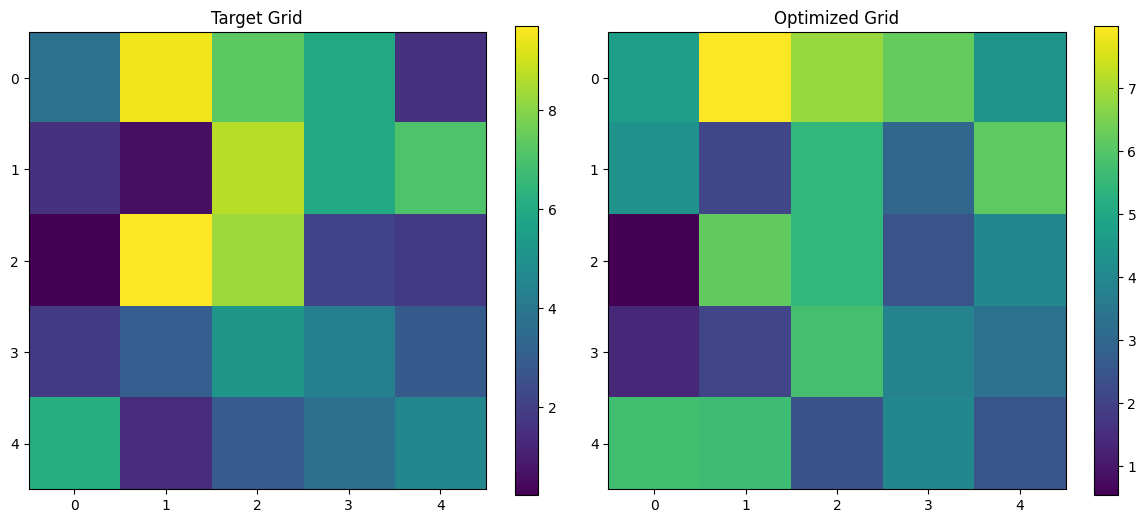

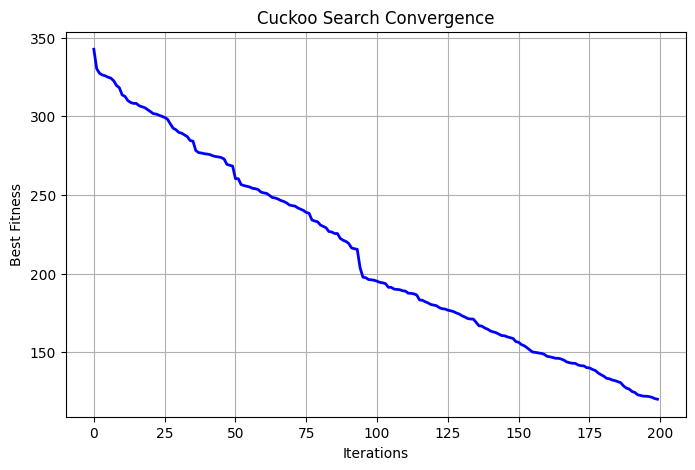

In [ ]:

# =====================================================
# CUCKOO SEARCH ALGORITHM FOR 2D GRID OPTIMIZATION
# =====================================================

import numpy as np
import matplotlib.pyplot as plt
from math import gamma


# -----------------------------------------------------
# 1. LEVY FLIGHT FUNCTION
# -----------------------------------------------------

def levy_flight(beta=1.5, size=None):

    sigma = (
        gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, size)
    v = np.random.normal(0, 1, size)

    step = u / np.maximum(np.abs(v), 1e-12) ** (1 / beta)

    return step


# -----------------------------------------------------
# 2. OBJECTIVE FUNCTION
# -----------------------------------------------------

def objective_function(grid, target):

    # Difference between optimized grid and target grid
    error = np.sum((grid - target) ** 2)

    # Smoothness penalty
    smoothness = (
        np.sum(np.diff(grid, axis=0) ** 2)
        + np.sum(np.diff(grid, axis=1) ** 2)
    )

    fitness = error + 0.1 * smoothness

    return fitness


# -----------------------------------------------------
# 3. CUCKOO SEARCH ALGORITHM
# -----------------------------------------------------

def cuckoo_search(
    target,
    n=25,
    pa=0.25,
    max_iter=200,
    lower_bound=0,
    upper_bound=10,
    alpha=0.01,
    beta=1.5
):

    grid_size = target.shape[0]

    # Initialize nests
    nests = np.random.uniform(
        lower_bound,
        upper_bound,
        (n, grid_size, grid_size)
    )

    # Evaluate initial population
    fitness = np.array([
        objective_function(x, target)
        for x in nests
    ])

    # Find initial best solution
    best_index = np.argmin(fitness)

    best_solution = nests[best_index].copy()
    best_fitness = fitness[best_index]

    # Store convergence history
    history = []

    # Main optimization loop
    for iteration in range(max_iter):

        # ---------------------------------------------
        # STEP 1: GENERATE NEW SOLUTIONS USING LEVY FLIGHT
        # ---------------------------------------------

        for i in range(n):

            step = levy_flight(beta, nests[i].shape)

            new_solution = (
                nests[i]
                + alpha * step * (nests[i] - best_solution)
            )

            new_solution = np.clip(
                new_solution,
                lower_bound,
                upper_bound
            )

            new_fitness = objective_function(
                new_solution, target
            )

            # -----------------------------------------
            # STEP 2: SELECT RANDOM NEST
            # -----------------------------------------

            j = np.random.randint(0, n)

            # -----------------------------------------
            # STEP 3: REPLACE IF BETTER
            # -----------------------------------------

            if new_fitness < fitness[j]:

                nests[j] = new_solution.copy()
                fitness[j] = new_fitness

        # ---------------------------------------------
        # STEP 4: ABANDON WORST NESTS
        # ---------------------------------------------

        abandon_count = int(pa * n)

        if abandon_count > 0:

            worst_indices = np.argsort(fitness)[
                -abandon_count:
            ]

            # Generate new solutions for abandoned nests
            for j in worst_indices:

                step = levy_flight(
                    beta, (grid_size, grid_size)
                )

                new_solution = (
                    best_solution + alpha * step
                )

                new_solution = np.clip(
                    new_solution,
                    lower_bound,
                    upper_bound
                )

                nests[j] = new_solution.copy()

                fitness[j] = objective_function(
                    new_solution, target
                )

        # ---------------------------------------------
        # STEP 5: PRESERVE GLOBAL BEST
        # ---------------------------------------------

        current_best = np.argmin(fitness)

        if fitness[current_best] < best_fitness:

            best_fitness = fitness[current_best]

            best_solution = nests[current_best].copy()

        history.append(best_fitness)

        # ---------------------------------------------
        # STEP 6: DISPLAY PROGRESS
        # ---------------------------------------------

        if (iteration + 1) % 20 == 0:

            print(
                f"Iteration {iteration + 1:3d} | "
                f"Best Fitness = {best_fitness:.6f}"
            )

    return best_solution, best_fitness, history


# -----------------------------------------------------
# 4. INITIALIZE TARGET GRID
# -----------------------------------------------------

np.random.seed(42)

target_grid = np.random.uniform(
    0, 10, (5, 5)
)


# -----------------------------------------------------
# 5. EXECUTE CUCKOO SEARCH
# -----------------------------------------------------

best_grid, best_fitness, history = cuckoo_search(

    target=target_grid,

    n=25,

    pa=0.25,

    max_iter=200,

    lower_bound=0,

    upper_bound=10,

    alpha=0.01,

    beta=1.5
)


# -----------------------------------------------------
# 6. DISPLAY NUMERICAL RESULTS
# -----------------------------------------------------

print("\n========== RESULTS ==========")

print("\nTarget Grid:")
print(np.round(target_grid, 3))

print("\nOptimized Grid:")
print(np.round(best_grid, 3))

print("\nBest Fitness:")
print(round(best_fitness, 6))


# -----------------------------------------------------
# 7. VISUALIZE GRID RESULTS
# -----------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    target_grid,
    cmap="viridis",
    interpolation="nearest"
)

plt.colorbar()
plt.title("Target Grid")


plt.subplot(1, 2, 2)

plt.imshow(
    best_grid,
    cmap="viridis",
    interpolation="nearest"
)

plt.colorbar()
plt.title("Optimized Grid")


plt.tight_layout()
plt.show()


# -----------------------------------------------------
# 8. CONVERGENCE GRAPH
# -----------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history,
    color="blue",
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cuckoo Search Convergence")

plt.grid(True)
plt.show()
